In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from typing import Tuple
from tqdm import tqdm
import pandas as pd

### Simulación del potencial de membrana de dos neuronas con enlace sinápticop dirigido

La función `continuous_synapse` contiene un esquema de simulación del potencial de membrana de dos neuronas (neurona 1 presinápstica y neurona 2 postsináptica) en el que hay un flujo de información desde la neurona presináptica a la postináptica mediante un modelo de sinapsis mediante neurotransmidores (Neurotransmitter model). La dinámica de las neuronas es tipo Hodgkin–Huxley y la sinápsis de esquema contínuo en relación a la liberación de neurotransmisor. Se incorpora también el modelo de conductancia puntual estocástico (Point-conductance model) para simular el ruido de un sistema global que llega sobre la neurona presináptica. Además de esa corriente externa, la función permite añadir ruido blanco o coloreado sobre el potencial de ambas neuronas. 
La simulación permite ver gráficamente el potencial de la neurona postsináptica si no hubiera recibido corriente sináptica de la neurona presinática, con el objetivo de vislumbrar la afección de dicho contacto.

In [10]:
def continuous_synapse(
    T: float = 400,
    dt: float = 0.01,
    mu1: float = 0.0,
    theta1: float = 1.0,
    sigma1: float = 3.0,
    mu2: float = 0.0,
    theta2: float = 1.0,
    sigma2: float = 2.0,
    cte1: float = 4.0,
    cte2: float = 4.0,
    g_syn: float = 3.0,
    E_syn: float = 10.0,
    alpha: float = 100,
    beta: float = 50,
    Tmax: float = 1e-2,
    V_th: float = -40.0,
    k: float = 0.5,
    tau: float = 1.0,
    tau_e = 2.7,
    std_e = 0.03,
    tau_i = 10.5,
    std_i = 0.006,
    use_OU_I1: bool = False,
    use_OU_I2: bool = False,
    plot: bool = True,
) -> Tuple[np.ndarray, np.ndarray]:
    
    """ Simulation of the membrane potentials of two neurons (presynaptic neuron 1 and postsynaptic neuron 2), with information flow from the 
    presynaptic to the postsynaptic neuron through a neurotransmitter-based synaptic model (Neurotransmitter model). A stochastic point-conductance 
    model (Point-conductance model) is also incorporated to simulate the noise from a global system input reaching the presynaptic neuron (I_syn_sistem). 
    In addition to this external input, the function allows white or colored noise to be added to the membrane potential of both neurons (I1 and I2).
    The OU noise is implemented with the deterministic formula solution 
    The accoplated EDOs of HH simulator are solve with the exponential method.   
    
        Parameters
    ----------
    T :
        Total simulation time.

    dt :
        Time step.

    mu1, theta1, sigma1 :
        Parameters of noise I1 for neuron 1 (theta1 only for OU).

    mu2, theta2 sigma2 :
        Parameters of noise I2 for neuron 2  (theta2 only for OU).

    cte1, cte2 :
        Constant input currents added to each neuron.

    g_syn :
        Synaptic strength. A key parameter used to regulate the level of influence Neuron 1 exerts over Neuron 2.

    E_syn :
        Synaptic reversal potential. Determines whether the synapse is excitatory or inhibitory and to what degree. 
        The higher the value (more positive), the more excitatory the synapse becomes.

    alpha, beta :
        Synaptic kinetics parameters. Alpha regulates the binding rate of receptors to the neurotransmitter (how fast the channels open) 
        and beta regulates the channel closing rate (how fast the signal decays). 

    Tmax :
        Maximum neurotransmitter release. Increasing this value generally results in a higher synaptic current.

    V_th :
        Threshold for neurotransmitter release. A lower value makes the presynaptic neuron more sensitive.

    k :
        Slope of the sigmoid activation. A smaller k results in a steeper (more abrupt) slope, leading to higher neurotransmitter release for the 
        same presynaptic potential.
        
    tau:
        Delay parameter in the transfer of information between neurons.

    tau_e, std_e:
        Parameters of Ornstein-Uhlenbeck noise for ge (excitatory conductance of I_syn_sistem).

    tau_i, std_i:
        Parameters of Ornstein-Uhlenbeck noise for gi (inhibitory conductance of I_syn_sistem).
        
    use_OU_I1, use_OU_I2:
        If True, Ii noise is OU. If false, then the noise Ii is Gaussian.
        
    plot :
        If True, display the simulation plots. If False, no plots are shown.

    Returns
    -------
    V1 :
        Membrane potential of neuron 1.

    V2 :
        Membrane potential of neuron 2 (with synaptic coupling).
    """

    # ======================
    # PARÁMETROS HH
    # ======================
    C = 1.0
    gNa, gK, gL = 120.0, 36.0, 0.3
    ENa, EK, EL = 50.0, -77.0, -54.4

    # ======================
    # FUNCIONES HH
    # ======================
    def get_rates(V):
        am = 0.1*(V+40)/(1 - np.exp(-(V+40)/10))
        bm = 4*np.exp(-(V+65)/18)
        ah = 0.07*np.exp(-(V+65)/20)
        bh = 1/(1 + np.exp(-(V+35)/10))
        an = 0.01*(V+55)/(1 - np.exp(-(V+55)/10))
        bn = 0.125*np.exp(-(V+65)/80)
        return am, bm, ah, bh, an, bn

    # ======================
    # TIEMPO
    # ======================
    n_steps = int(T / dt)
    delay_steps = int(tau / dt)
    t_eval = np.linspace(0, T, n_steps)

    # ======================
    # RUIDOS (vectorizado)
    # ======================
    if use_OU_I1:
        I1 = np.zeros(n_steps)
        exp_term = np.exp(-theta1 * dt)
        std_term = sigma1 * np.sqrt((1 - np.exp(-2 * theta1 * dt)) / (2 * theta1))
        for i in range(n_steps - 1):
            xi = np.random.randn()
            I1[i+1] = I1[i] * exp_term + mu1 * (1 - exp_term) + std_term * xi 
        I1 += cte1   
    else:
        I1 = cte1 + mu1 + sigma1 * np.random.randn(n_steps)
        
    if use_OU_I2:
        I2 = np.zeros(n_steps)
        exp_term = np.exp(-theta2 * dt)
        std_term = sigma2 * np.sqrt((1 - np.exp(-2 * theta2 * dt)) / (2 * theta2))
        for i in range(n_steps - 1):
            xi = np.random.randn() 
            I2[i+1] = I2[i] * exp_term + mu2 * (1 - exp_term) + std_term * xi    
        I2 += cte2        
    else:
        I2 = cte2 + mu2 + sigma2 * np.random.randn(n_steps) 

    # ======================
    # SINAPSIS (entorno --> neurona 1)
    # ======================
    # Excitatorio
    ge0 = 0.0121
    Ee = 0.0
    # Inhibitorio
    gi0 = 0.0573
    Ei = -75.0
    
    ge = np.zeros(n_steps)
    gi = np.zeros(n_steps)
    ge[0], gi[0] = ge0, gi0
    
    # ge
    exp_e = np.exp(-dt / tau_e)
    std_term_e = std_e * np.sqrt(1 - np.exp(-2 * dt / tau_e))
    
    # gi
    exp_i = np.exp(-dt / tau_i)
    std_term_i = std_i * np.sqrt(1 - np.exp(-2 * dt / tau_i))

    # ======================
    # SINAPSIS (neurona 1 --> neurona 2)
    # ======================
    def T_release(V_pre):
        return Tmax / (1 + np.exp(-(V_pre - V_th)/k))

    # ======================
    # INICIALIZACIÓN
    # ======================
    V1, m1, h1, n1 = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
    V2, m2, h2, n2 = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
    V2_no, m2n, h2n, n2n = np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps), np.zeros(n_steps)
    r = np.zeros(n_steps)

    V1[0] = V2[0] = V2_no[0] = -65.0
    am, bm, ah, bh, an, bn = get_rates(V1[0])
    m1[0] = m2[0] = m2n[0] = am/(am+bm)
    h1[0] = h2[0] = h2n[0] = ah/(ah+bh)
    n1[0] = n2[0] = n2n[0] = an/(an+bn)

    # ======================
    # BUCLE DE INTEGRACIÓN
    # Canales iónicos mediante integración exponencial y potencial de membrana con Euler explícito 
    # ======================
    for i in range(n_steps - 1):
        # Corriente entrada neurona 1 desde el sistema
        ge[i+1] = ge0 + (ge[i] - ge0) * exp_e + std_term_e * np.random.randn()
        gi[i+1] = gi0 + (gi[i] - gi0) * exp_i + std_term_i * np.random.randn()
        
        ge[i+1] = max(ge[i+1], 0)
        gi[i+1] = max(gi[i+1], 0)

        I_syn_sistem = ge[i] * (V1[i] - Ee) + gi[i] * (V1[i] - Ei) 

        # ---- Neurona 1 HH ----
        am1, bm1, ah1, bh1, an1, bn1 = get_rates(V1[i]) 

        tau_m = 1.0 / (am1 + bm1)  
        tau_h = 1.0 / (ah1 + bh1)  
        tau_n = 1.0 / (an1 + bn1)
        
        m_inf = am1 / (am1 + bm1)  
        h_inf = ah1 / (ah1 + bh1)  
        n_inf = an1 / (an1 + bn1)

        m1[i+1] = m_inf + (m1[i] - m_inf) * np.exp(-dt / tau_m) 
        h1[i+1] = h_inf + (h1[i] - h_inf) * np.exp(-dt / tau_h)                                                   
        n1[i+1] = n_inf + (n1[i] - n_inf) * np.exp(-dt / tau_n)
        
        I_ion1 = gNa*(m1[i]**3)*h1[i]*(V1[i]-ENa) + gK*(n1[i]**4)*(V1[i]-EK) + gL*(V1[i]-EL)           
        V1[i+1] = V1[i] + (I1[i] - I_ion1 - I_syn_sistem) * dt / C 

        # ---- Sinapsis con delay neurona 1 --> neurona 2
        if i - delay_steps >= 0:
            V_pre_delayed = V1[i - delay_steps]
        else:
            V_pre_delayed = V1[0] 

        Tt = T_release(V_pre_delayed)

        r[i+1] = r[i] + (alpha*Tt*(1 - r[i]) - beta*r[i]) * dt
        I_syn = g_syn * r[i] * (V2[i] - E_syn)

        # ---- Neurona 2 (CON sinapsis) ----
        am2, bm2, ah2, bh2, an2, bn2 = get_rates(V2[i])
        
        tau_m = 1.0 / (am2 + bm2)  
        tau_h = 1.0 / (ah2 + bh2) 
        tau_n = 1.0 / (an2 + bn2)
        
        m_inf = am2 / (am2 + bm2)  
        h_inf = ah2 / (ah2 + bh2)     
        n_inf = an2 / (an2 + bn2)

        m2[i+1] = m_inf + (m2[i] - m_inf) * np.exp(-dt / tau_m) 
        h2[i+1] = h_inf + (h2[i] - h_inf) * np.exp(-dt / tau_h)                                                   
        n2[i+1] = n_inf + (n2[i] - n_inf) * np.exp(-dt / tau_n)
        
        I_ion2 = gNa*(m2[i]**3)*h2[i]*(V2[i]-ENa) + gK*(n2[i]**4)*(V2[i]-EK) + gL*(V2[i]-EL)
        V2[i+1] = V2[i] + (I2[i] - I_syn - I_ion2) * dt / C

        # ---- Neurona 2 (SIN sinapsis) ----
        am2n, bm2n, ah2n, bh2n, an2n, bn2n = get_rates(V2_no[i])
        
        tau_m = 1.0 / (am2n + bm2n)  
        tau_h = 1.0 / (ah2n + bh2n) 
        tau_n = 1.0 / (an2n + bn2n)
        
        m_inf = am2n / (am2n + bm2n)  
        h_inf = ah2n / (ah2n + bh2n)   
        n_inf = an2n / (an2n + bn2n)
        
        m2n[i+1] = m_inf + (m2n[i] - m_inf) * np.exp(-dt / tau_m) 
        h2n[i+1] = h_inf + (h2n[i] - h_inf) * np.exp(-dt / tau_h)                                                   
        n2n[i+1] = n_inf + (n2n[i] - n_inf) * np.exp(-dt / tau_n)  
        
        I_ion2n = gNa*(m2n[i]**3)*h2n[i]*(V2_no[i]-ENa) + gK*(n2n[i]**4)*(V2_no[i]-EK) + gL*(V2_no[i]-EL)
        V2_no[i+1] = V2_no[i] + (I2[i] - I_ion2n) * dt / C

    # ======================
    # PLOTS
    # ======================
    if plot:
        plt.figure(figsize=(12,9))
    
        ax1 = plt.subplot(3,1,1)
        ax1.plot(t_eval, V1)
        ax1.set_title("Neurona presináptica (OU)")
        ax1b = ax1.twinx()
        ax1b.plot(t_eval, I1, alpha=0.3)
    
        ax2 = plt.subplot(3,1,2)
        ax2.plot(t_eval, V2_no)
        ax2.set_title("Postsináptica SIN sinapsis")
        ax2b = ax2.twinx()
        ax2b.plot(t_eval, I2, alpha=0.3)
    
        ax3 = plt.subplot(3,1,3)
        ax3.plot(t_eval, V2)
        ax3.set_title("Postsináptica CON sinapsis")
        ax3b = ax3.twinx()
        ax3b.plot(t_eval, I2, alpha=0.3)
    
        plt.tight_layout()
        plt.show()

    return V1, V2

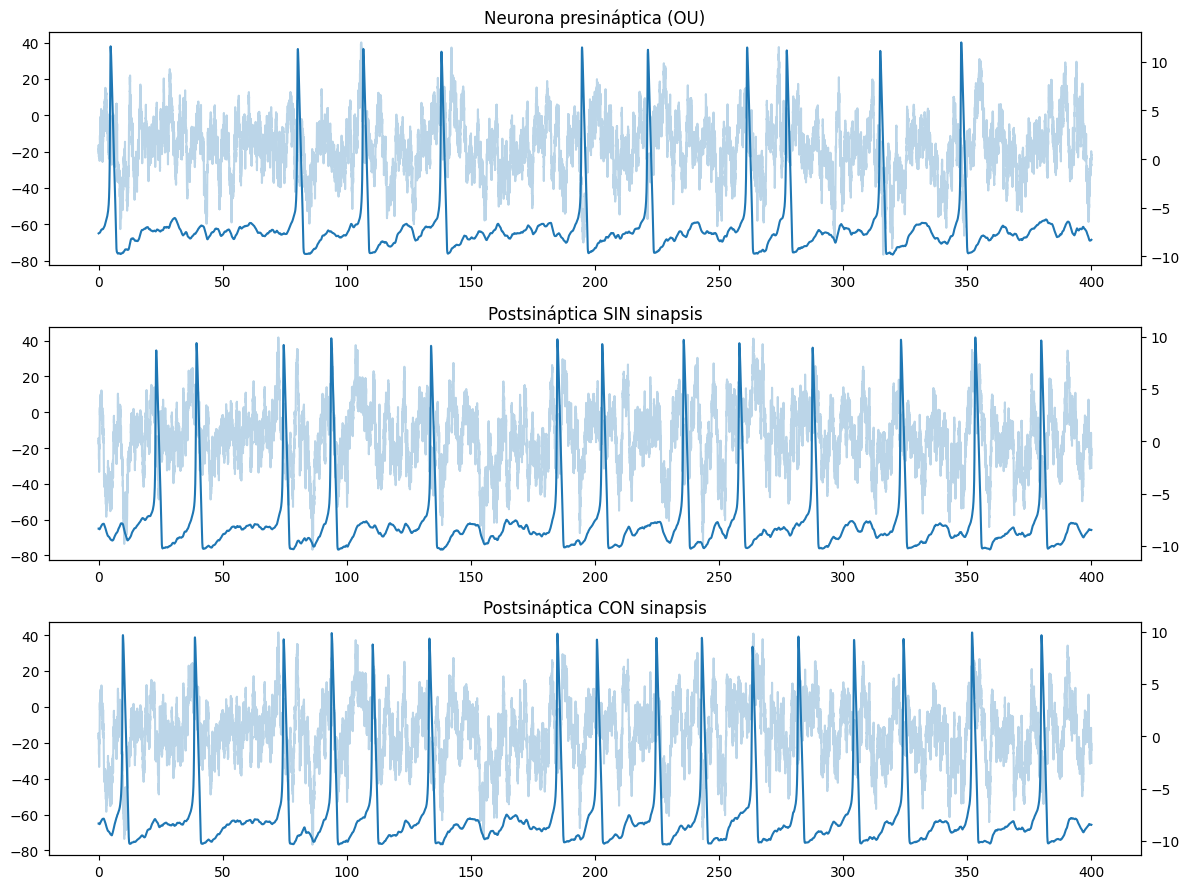

In [17]:
V1, V2 = continuous_synapse(mu1 = 0.0, theta1 = 1.0, sigma1 = 4.0, mu2 = 0.0, theta2 = 1.0, sigma2 = 4.0, cte1 = 1.0, cte2 = 0.3, tau_e = 2.7, std_e = 0.003, tau_i = 10.5, std_i = 0.006, use_OU_I1 = True, use_OU_I2 = True, plot = True)

La función `pulse_synapse`, similarmente a la anterior, contiene un esquema de simulación del potencial de membrana de dos neuronas (neurona 1 presinápstica y neurona 2 postsináptica) en el que hay un flujo de información desde la neurona presináptica a la postináptica mediante un modelo de sinapsis mediante neurotransmidores (Neurotransmitter model). La diferencia es que en este caso las neuronas obedecen una dinámica tipo Izhikevich y la liberación de neurotransmisor es de tipo pulso fijo. En este caso, solo se añade una corriente constante a cada neurona (I1 e I2) de magnitud regulable.

In [19]:
def pulse_synapse(
    T: float = 1000,
    dt: float = 0.1,
    a1: float = 0.01,
    b1: float = 0.26,
    c1: float = -65.0,
    d1: float = 2.0,
    a2: float = 0.02,
    b2: float = 0.25,
    c2: float = -65.0,
    d2: float = 6.0,
    I1_const: float = 4.5,
    I2_const: float = 1.0,
    g_syn: float = 0.1,
    E_syn: float = -80.0,
    alpha: float = 5.0,
    beta: float = 0.1,
    Tmax: float = 1,
    V_th: float = 0.0,
    tmax: float = 30.0,
    tau_delay: float = 0.0,
    plot: bool = True,
) -> Tuple[np.ndarray, np.ndarray]:
    
    """ Simulation of two Izhikevich neurons coupled through a fixed-pulse chemical synapse.
    
    Neuron 1:
    Izhikevich model + constant input current I_1
    
    Neuron 2:
    Izhikevich model + constant input current I_2 + synaptic current


    Parameters
    ----------
    T :
        Total simulation time.

    dt :
        Time step.

    a1, b1, c1, d1:
        Parameters of neuron 1.

    a2, b2, c2, d2:
        Parameters of neuron 2.

    I1_const, I2_const :
        Constant input currents added to each neuron.

    g_syn :
        Synaptic strength. A key parameter used to regulate the level of influence Neuron 1 exerts over Neuron 2.

    E_syn :
        Synaptic reversal potential. Determines whether the synapse is excitatory or inhibitory and to what degree. 
        The higher the value (more positive), the more excitatory the synapse becomes.

    alpha, beta :
        Synaptic kinetics parameters. Alpha regulates the binding rate of receptors to the neurotransmitter (how fast the channels open) 
        and beta regulates the channel closing rate (how fast the signal decays). 

    Tmax :
        Maximum neurotransmitter release. Increasing this value generally results in a higher synaptic current.

    V_th :
        Threshold for neurotransmitter release. A lower value makes the presynaptic neuron more sensitive.
        
    tau_delay:
        Delay parameter in the transfer of information between neurons.
        
    plot :
        If True, display the simulation plots. If False, no plots are shown.

    Returns
    -------
    V1 :
        Membrane potential of neuron 1.

    V2 :
        Membrane potential of neuron 2 (with synaptic coupling).
    """

    # ======================
    # TIEMPO
    # ======================
    n_steps = int(T / dt)
    t_eval = np.arange(0, T, dt)
    delay_steps = int(tau_delay / dt)
    
    # ======================
    # CORRIENTES CONSTANTES
    # ======================
    I1 = np.ones(n_steps) * I1_const
    I2 = np.ones(n_steps) * I2_const

    # ======================
    # VARIABLES IZHIKEVICH
    # ======================
    V1 = np.zeros(n_steps)
    U1 = np.zeros(n_steps)
    V2 = np.zeros(n_steps)
    U2 = np.zeros(n_steps)

    V1[0] = -65
    U1[0] = b1 * V1[0]
    V2[0] = -65
    U2[0] = b2 * V2[0]
    
    # ======================
    # SINAPSIS
    # ======================
    r = np.zeros(n_steps)
    release_steps = int(tmax/dt)
    release_counter = 0
    V_pre_previous = V1[0]
    
    # ======================
    # BUCLE SIMULACIÓN
    # ======================
    for i in range(n_steps-1):
        
        # NEURONA 1
        v = V1[i]
        u = U1[i]
        dv = (0.04*v**2+5*v+140-u+I1[i]) * dt
        du = (a1*(b1*v-u)) * dt
        V1[i+1] = v + dv
        U1[i+1] = u + du

        if V1[i+1] >= 30:
            V1[i] = 30.0
            V1[i+1] = c1
            U1[i+1] += d1

        # SINAPSIS
        if i-delay_steps >= 0:
            V_pre = V1[i-delay_steps]
        else:
            V_pre = V1[0]

        if V_pre_previous < V_th and V_pre >= V_th:
            release_counter = release_steps
        if release_counter > 0:
            Tt = Tmax
            release_counter -= 1
        else:
            Tt = 0.0
            
        V_pre_previous = V_pre

        r[i+1] = (r[i]+(alpha*Tt*(1-r[i])- beta*r[i])*dt)
        I_syn = g_syn*r[i+1]*(E_syn - V2[i])

        # NEURONA 2
        v = V2[i]
        u = U2[i]
        dv = (0.04*v**2+5*v+140-u+I2[i]-I_syn) * dt
        du = (a2*(b2*v-u)) * dt
        V2[i+1] = v + dv
        U2[i+1] = u + du

        if V2[i+1] >= 30:
            V2[i] = 30.0
            V2[i+1] = c2
            U2[i+1] += d2

    # ======================
    # PLOTS
    # ======================
    if plot:
        plt.figure(figsize=(12,8))
        ax1 = plt.subplot(2,1,1)
        ax1.plot(t_eval, V1)
        ax1.set_title("Neurona 1 Izhikevich (presináptica)")
        ax1.set_ylabel("V (mV)")
        ax1b = ax1.twinx()
        ax1b.plot(t_eval, I1, alpha=0.3)
        ax1b.set_ylabel("I1")
        ax2 = plt.subplot(2,1,2)
        ax2.plot(t_eval, V2)
        ax2.set_title("Neurona 2 Izhikevich + sinapsis")
        ax2.set_xlabel("Tiempo")
        ax2.set_ylabel("V (mV)")
        ax2b = ax2.twinx()
        ax2b.plot(t_eval, I2, alpha=0.3)
        ax2b.set_ylabel("I2")
        plt.tight_layout()
        plt.show()


    return V1, V2

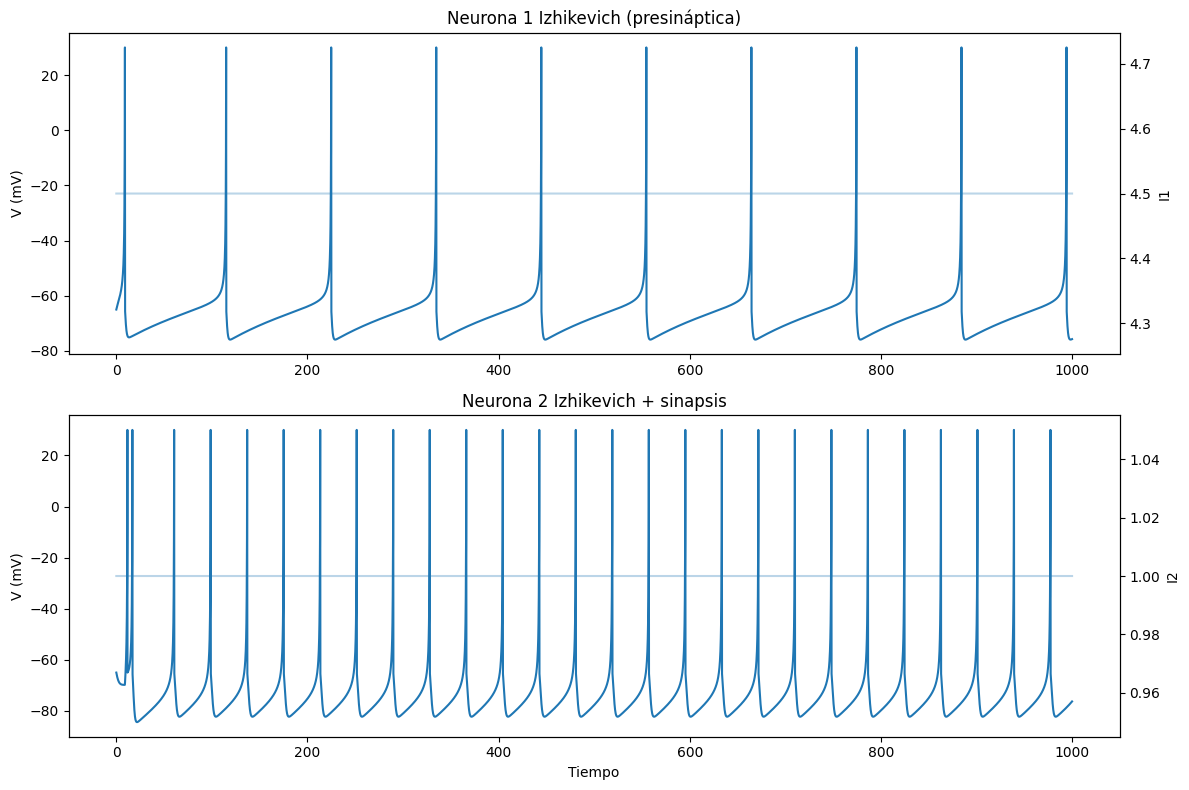

In [20]:
V1, V2 = pulse_synapse(a1=0.02, b1=0.2, c1=-65.0, d1=8.0, a2=0.02, b2=0.2, c2=-65.0, d2=8.0, alpha=4.795, beta=0.003274, g_syn=0.7056, tmax=396.811)